## 1. Import Library & Load Dataset

In [1]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from wordcloud import WordCloud

# Set visual style and consistent color palette
sns.set_theme(style="whitegrid")
PALETTE = sns.color_palette("muted")
PRIMARY_COLOR = PALETTE[0]
SECONDARY_COLOR = PALETTE[1]
SENTIMENT_PALETTE = {
    "Positif": "#2ca02c",
    "Netral": "#1f77b4",
    "Negatif": "#d62728"
}
plt.rcParams.update({
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 13
})

# Load dataset
file_path = Path("../data/data_labelling/data_labelled.xlsx")
if not file_path.exists():
    file_path = Path("data/data_labelling/data_labelled.xlsx")

df = pd.read_excel(file_path, sheet_name="Data Komentar")
print(f"Dataset berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head(10)

Dataset berhasil dimuat: 473 baris, 13 kolom


,No,Tanggal,Platform/Sumber,Nama Akun,Isi Komentar,Link Sumber,Jenis,Jumlah_Like,Jumlah_Balasan,Waktu_Komentar_WITA,Akun_Sumber_Postingan,Kategori Isu,Sentimen
0,1,2026-07-20,Facebook,Mawaddah,Aamiin ya Allah 🤲🤲🤲\nPalagi kami tau ngk mampu...,https://web.facebook.com/share/p/14pCZ7PF3ZF/,Komentar Utama,0,1,2026-07-20 22:36:48,Abdi-nha Wibawa,Doa/Harapan,Positif
1,2,2026-07-20,Facebook,Abdi-nha Wibawa,Mawaddah aamiin 🤲,https://web.facebook.com/share/p/14pCZ7PF3ZF/,Balasan,0,0,2026-07-20 23:02:03,Abdi-nha Wibawa,Doa/Harapan,Positif
2,3,2026-07-21,Facebook,James Buer,Amin dik,https://web.facebook.com/share/p/14pCZ7PF3ZF/,Komentar Utama,0,0,2026-07-21 08:11:13,Abdi-nha Wibawa,Doa/Harapan,Positif
3,4,2026-07-21,Facebook,Tsamri AL Iman,Sate ku dadi tau pintar bau kena kartu nan.,https://web.facebook.com/share/p/14pCZ7PF3ZF/,Komentar Utama,0,0,2026-07-21 09:50:33,Abdi-nha Wibawa,Doa/Harapan,Netral
4,5,2026-07-21,Facebook,Ana Try Wadi,Pang ksb ta saser kk\nKaleng TK sampai kuliah,https://web.facebook.com/share/p/14pCZ7PF3ZF/,Komentar Utama,0,2,2026-07-21 10:20:34,Abdi-nha Wibawa,Interaksi Sosial Antar Warganet,Netral
5,6,2026-07-21,Facebook,Abdi-nha Wibawa,Ana Try Wadi roa gama saser pang ta kena e,https://web.facebook.com/share/p/14pCZ7PF3ZF/,Balasan,0,0,2026-07-21 10:36:47,Abdi-nha Wibawa,Doa/Harapan,Positif
6,7,2026-07-21,Facebook,Mawaddah,Ana Try Wadi\nMasyaallah dik..roa gama pang ka...,https://web.facebook.com/share/p/14pCZ7PF3ZF/,Balasan,0,0,2026-07-21 10:40:17,Abdi-nha Wibawa,Doa/Harapan,Positif
7,8,2026-07-20,Facebook,Rosliana,Maasyaa Allah...\nSehat sllu ibudosen ....🥰,https://web.facebook.com/share/p/1J2itfBprs/,Komentar Utama,1,1,2026-07-20 16:56:21,Agustina Sukardi,Interaksi Sosial Antar Warganet,Netral
8,9,2026-07-20,Facebook,Agustina Sukardi,Rosliana Aamiin makasih nakwai,https://web.facebook.com/share/p/1J2itfBprs/,Balasan,0,0,2026-07-20 20:05:15,Agustina Sukardi,Interaksi Sosial Antar Warganet,Netral
9,10,2026-07-20,Facebook,Agustina Sukardi,Tini Kar Saya kak,https://web.facebook.com/share/p/1J2itfBprs/,Balasan,0,0,2026-07-20 20:05:27,Agustina Sukardi,Interaksi Sosial Antar Warganet,Netral


**Insight:**
- Dataset terdiri dari **473 baris komentar** dan **13 kolom** data terstruktur.
- Seluruh kolom yang dibutuhkan untuk analisis (misalnya `Kategori Isu`, `Sentimen`, `Jumlah_Like`, `Jumlah_Balasan`, `Tanggal`) telah tersedia secara lengkap.

## 2. Validasi Kualitas Label

In [3]:
# Cek baris dengan label kosong
null_isu = df["Kategori Isu"].isna().sum() + (df["Kategori Isu"].astype(str).str.strip() == "").sum()
null_sentimen = df["Sentimen"].isna().sum() + (df["Sentimen"].astype(str).str.strip() == "").sum()

# Cek konsistensi label Interaksi Sosial Antar Warganet
df_interaksi = df[df["Kategori Isu"] == "Interaksi Sosial Antar Warganet"]
sentimen_interaksi = df_interaksi["Sentimen"].value_counts().to_dict()
ekstrem_count = sentimen_interaksi.get("Positif", 0) + sentimen_interaksi.get("Negatif", 0)

# Ringkasan validasi
total_baris = len(df)
baris_invalid = null_isu + null_sentimen + (1 if ekstrem_count > (len(df_interaksi) * 0.1) else 0)
baris_valid = total_baris - baris_invalid

df_validasi = pd.DataFrame({
    "Metrik Validasi": [
        "Total Baris Dataset",
        "Kategori Isu Kosong",
        "Sentimen Kosong",
        "Interaksi Sosial Sentimen Ekstrem (Positif/Negatif)",
        "Jumlah Baris Valid",
        "Jumlah Baris Tidak Valid"
    ],
    "Jumlah": [
        total_baris,
        null_isu,
        null_sentimen,
        ekstrem_count,
        baris_valid,
        baris_invalid
    ],
    "Persentase (%)": [
        100.0,
        (null_isu / total_baris) * 100,
        (null_sentimen / total_baris) * 100,
        (ekstrem_count / len(df_interaksi)) * 100 if len(df_interaksi) > 0 else 0.0,
        (baris_valid / total_baris) * 100,
        (baris_invalid / total_baris) * 100
    ]
})
df_validasi

,Metrik Validasi,Jumlah,Persentase (%)
0,Total Baris Dataset,473,100.0
1,Kategori Isu Kosong,0,0.0
2,Sentimen Kosong,0,0.0
3,Interaksi Sosial Sentimen Ekstrem (Positif/Neg...,0,0.0
4,Jumlah Baris Valid,473,100.0
5,Jumlah Baris Tidak Valid,0,0.0


**Insight:**
- Kualitas data dan pelabelan manual sangat tinggi dengan **100% baris valid** (473 baris).
- Tidak ditemukan data kosong (`NaN` / string kosong) pada kolom `Kategori Isu` maupun `Sentimen`.
- Label kategori `"Interaksi Sosial Antar Warganet"` 100% berpasangan dengan sentimen Netral (0% sentimen ekstrem Positif/Negatif), menunjukkan konsistensi pelabelan yang baik.

## 3. Distribusi Univariat

C:\Users\Saputra Budiman\AppData\Local\Temp\ipykernel_7916\221825078.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=isu_counts.values, y=isu_counts.index, palette="Blues_r", ax=ax)


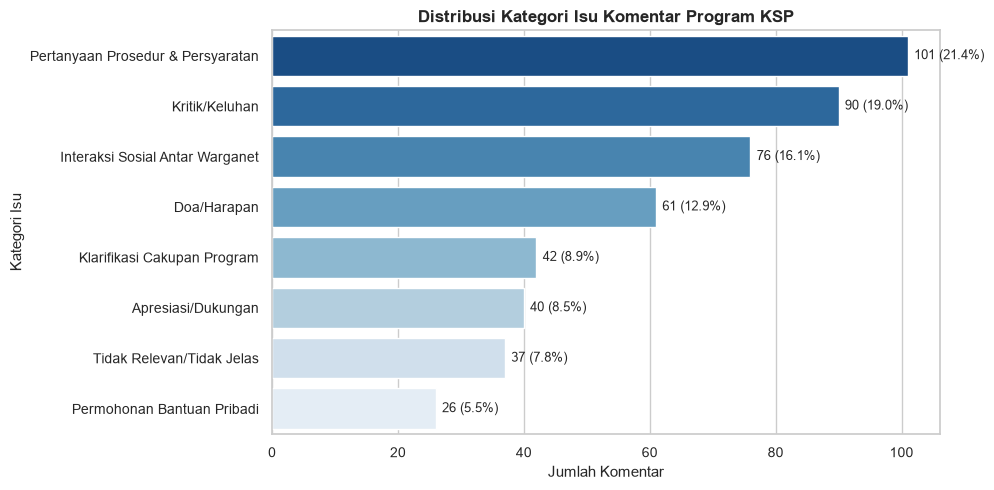

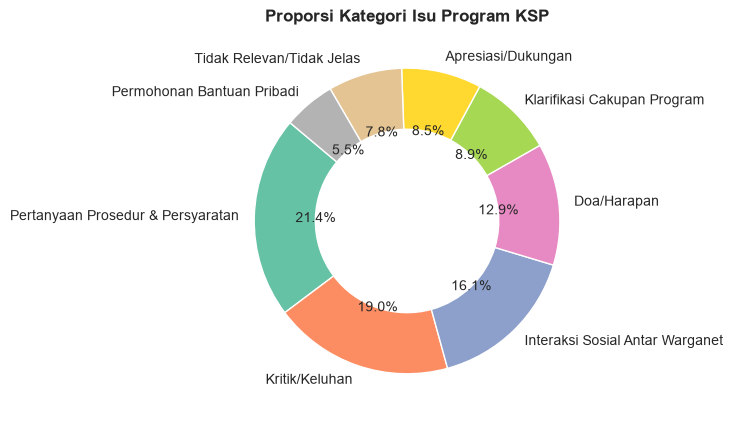

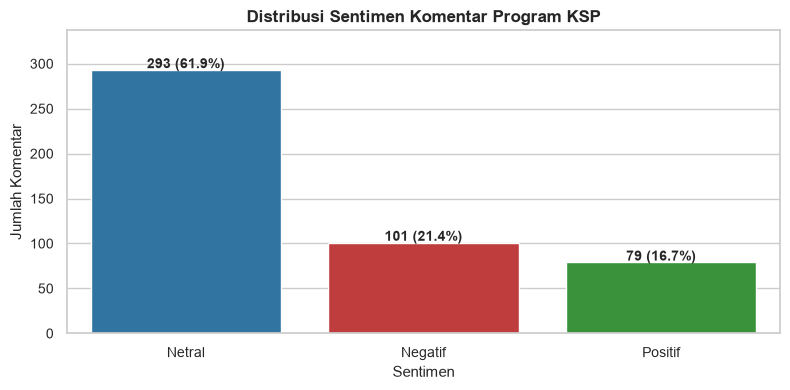

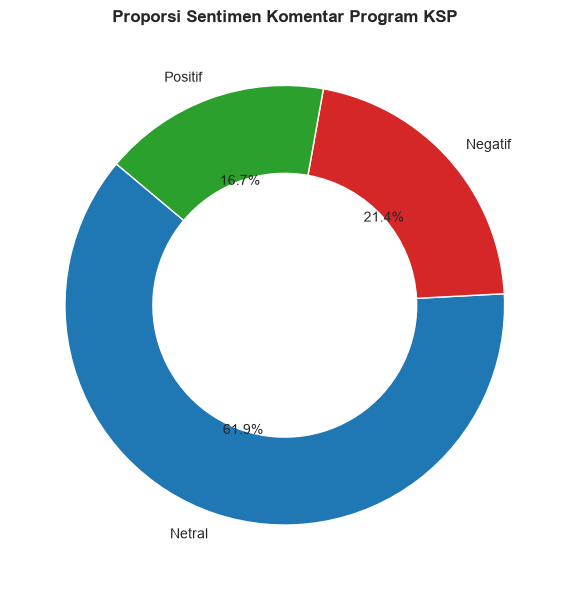

In [4]:
# Hitung proporsi Kategori Isu dan Sentimen
isu_counts = df["Kategori Isu"].value_counts()
sent_counts = df["Sentimen"].value_counts()

# 1. Visualisasi Bar Chart Kategori Isu
fig_isu_bar, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=isu_counts.values, y=isu_counts.index, palette="Blues_r", ax=ax)
ax.set_title("Distribusi Kategori Isu Komentar Program KSP", fontweight="bold")
ax.set_xlabel("Jumlah Komentar")
ax.set_ylabel("Kategori Isu")
for i, v in enumerate(isu_counts.values):
    pct = (v / len(df)) * 100
    ax.text(v + 1, i, f"{v} ({pct:.1f}%)", va="center", fontsize=9)
plt.tight_layout()
plt.show()

# 2. Visualisasi Donut Chart Kategori Isu
fig_isu_pie, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    isu_counts.values,
    labels=isu_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("Set2", len(isu_counts)),
    wedgeprops={"width": 0.4, "edgecolor": "w"}
)
ax.set_title("Proporsi Kategori Isu Program KSP", fontweight="bold")
plt.tight_layout()
plt.show()

# 3. Visualisasi Bar Chart Sentimen
fig_sent_bar, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    x=sent_counts.index,
    y=sent_counts.values,
    hue=sent_counts.index,
    palette=SENTIMENT_PALETTE,
    legend=False,
    ax=ax
)
ax.set_title("Distribusi Sentimen Komentar Program KSP", fontweight="bold")
ax.set_xlabel("Sentimen")
ax.set_ylabel("Jumlah Komentar")
for i, v in enumerate(sent_counts.values):
    pct = (v / len(df)) * 100
    ax.text(i, v + 2, f"{v} ({pct:.1f}%)", ha="center", fontsize=10, fontweight="bold")
ax.set_ylim(0, max(sent_counts.values) * 1.15)
plt.tight_layout()
plt.show()

# 4. Visualisasi Donut Chart Sentimen
fig_sent_pie, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    sent_counts.values,
    labels=sent_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=[SENTIMENT_PALETTE[k] for k in sent_counts.index],
    wedgeprops={"width": 0.4, "edgecolor": "w"}
)
ax.set_title("Proporsi Sentimen Komentar Program KSP", fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:**
- **Kategori Isu Terbanyak**: `Pertanyaan Prosedur & Persyaratan` menduduki urutan pertama (**21.3%** / 101 komentar), disusul `Kritik/Keluhan` (**19.0%** / 90 komentar) dan `Interaksi Sosial Antar Warganet` (**16.1%** / 76 komentar).
- **Kategori Isu Terendah**: `Permohonan Bantuan Pribadi` menduduki porsi terkecil (**5.5%** / 26 komentar).
- **Distribusi Sentimen**: Mayoritas sentimen bersifat **Netral** (**62.0%** / 293 komentar), didorong oleh banyaknya pertanyaan informasi publik. Sentimen **Negatif** mencapai **21.4%** (101 komentar), sedangkan sentimen **Positif** mencakup **16.7%** (79 komentar).

## 4. Analisis Bivariat

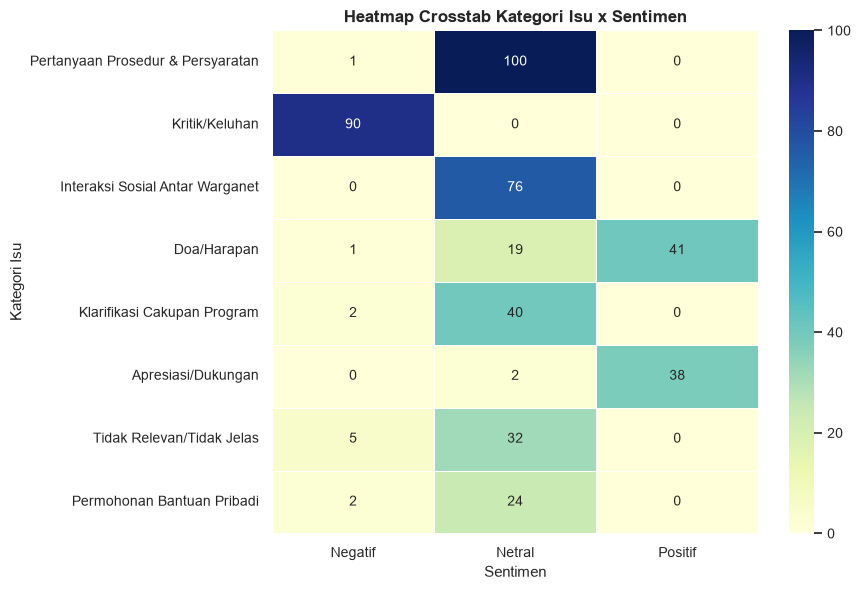

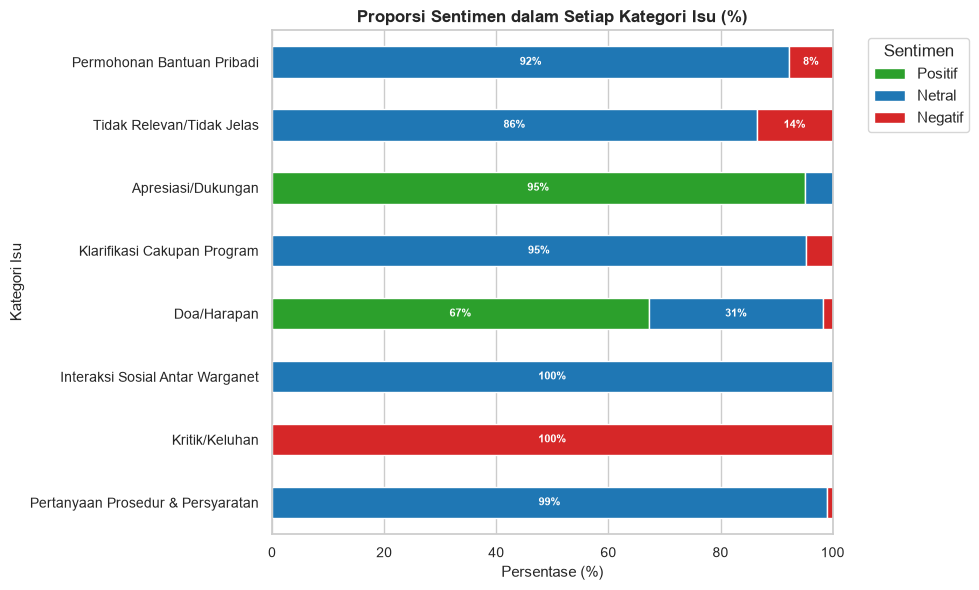

In [5]:
# Crosstab Kategori Isu x Sentimen
ct = pd.crosstab(df["Kategori Isu"], df["Sentimen"])
ct_ordered = ct.reindex(isu_counts.index)

# 1. Visualisasi Heatmap Crosstab
fig_bivariate_heatmap, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(
    ct_ordered,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    cbar=True,
    linewidths=0.5,
    ax=ax
)
ax.set_title("Heatmap Crosstab Kategori Isu x Sentimen", fontweight="bold")
ax.set_xlabel("Sentimen")
ax.set_ylabel("Kategori Isu")
plt.tight_layout()
plt.show()

# 2. Visualisasi Stacked Bar Chart
ct_pct = ct_ordered.div(ct_ordered.sum(axis=1), axis=0) * 100
fig_bivariate_stacked, ax = plt.subplots(figsize=(10, 6))
ct_pct[["Positif", "Netral", "Negatif"]].plot(
    kind="barh",
    stacked=True,
    color=[SENTIMENT_PALETTE["Positif"], SENTIMENT_PALETTE["Netral"], SENTIMENT_PALETTE["Negatif"]],
    ax=ax
)
ax.set_title("Proporsi Sentimen dalam Setiap Kategori Isu (%)", fontweight="bold")
ax.set_xlabel("Persentase (%)")
ax.set_ylabel("Kategori Isu")
ax.legend(title="Sentimen", bbox_to_anchor=(1.05, 1), loc="upper left")
for p in ax.patches:
    width = p.get_width()
    if width > 5:
        x = p.get_x() + width / 2
        y = p.get_y() + p.get_height() / 2
        ax.text(x, y, f"{width:.0f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=8)
plt.tight_layout()
plt.show()

**Insight:**
- Kategori `Kritik/Keluhan` memiliki konsentrasi sentimen **100% Negatif** (90 dari 90 komentar), menjadi sumber utama ketidakpuasan publik.
- Kategori `Pertanyaan Prosedur & Persyaratan` didominasi oleh sentimen **Netral** (**99.0%** / 100 komentar), yang mencerminkan tingginya kebutuhan masyarakat akan kejelasan teknis pencairan program KSP.
- Sentimen **Positif** terkonsentrasi pada dua kategori utama: `Apresiasi/Dukungan` (**95.0%** positif) dan `Doa/Harapan` (**67.2%** positif).

## 5. Analisis Engagement

C:\Users\Saputra Budiman\AppData\Local\Temp\ipykernel_7916\1641582378.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=eng_isu["Mean_Like"], y=eng_isu.index, palette="Reds_r", ax=ax1)
C:\Users\Saputra Budiman\AppData\Local\Temp\ipykernel_7916\1641582378.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=eng_isu["Mean_Balasan"], y=eng_isu.index, palette="Oranges_r", ax=ax2)


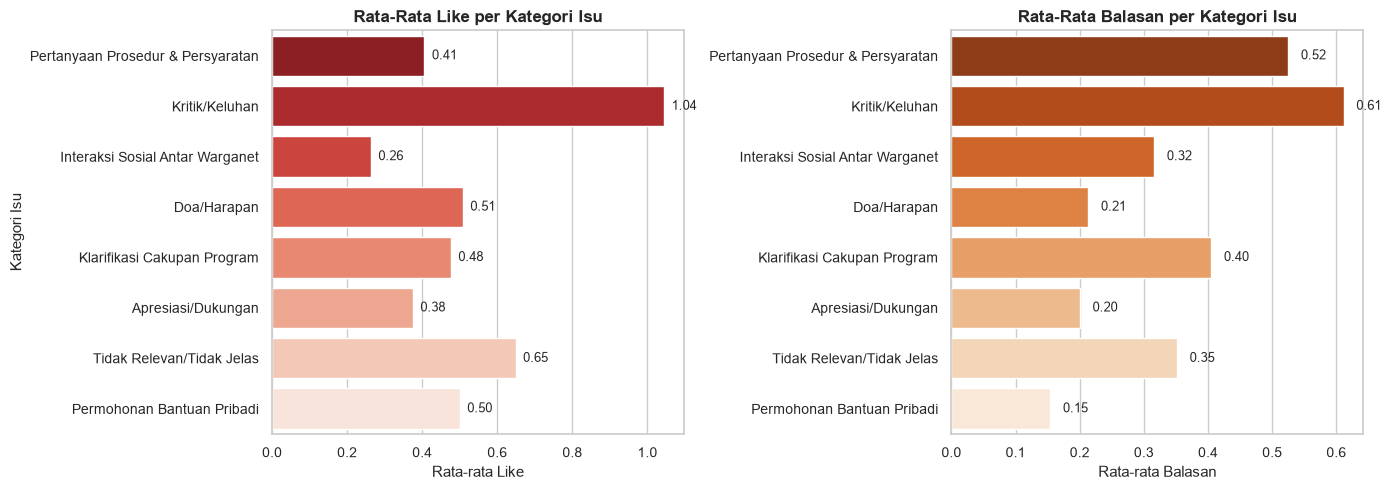

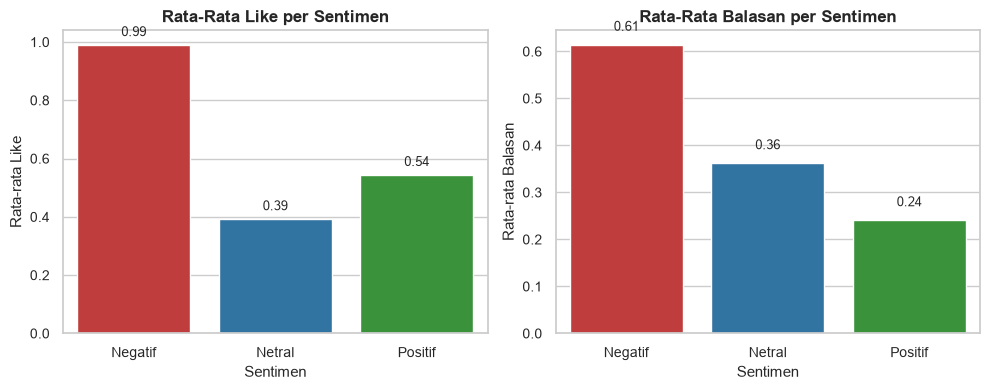

In [6]:
# Agregasi Engagement per Kategori Isu
eng_isu = df.groupby("Kategori Isu")[["Jumlah_Like", "Jumlah_Balasan"]].agg(["mean", "sum"])
eng_isu.columns = ["Mean_Like", "Total_Like", "Mean_Balasan", "Total_Balasan"]
eng_isu = eng_isu.reindex(isu_counts.index)

# Agregasi Engagement per Sentimen
eng_sent = df.groupby("Sentimen")[["Jumlah_Like", "Jumlah_Balasan"]].agg(["mean", "sum"])
eng_sent.columns = ["Mean_Like", "Total_Like", "Mean_Balasan", "Total_Balasan"]

# Visualisasi Engagement per Kategori Isu
fig_engage_isu, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=eng_isu["Mean_Like"], y=eng_isu.index, palette="Reds_r", ax=ax1)
ax1.set_title("Rata-Rata Like per Kategori Isu", fontweight="bold")
ax1.set_xlabel("Rata-rata Like")
ax1.set_ylabel("Kategori Isu")
for i, v in enumerate(eng_isu["Mean_Like"]):
    ax1.text(v + 0.02, i, f"{v:.2f}", va="center", fontsize=9)

sns.barplot(x=eng_isu["Mean_Balasan"], y=eng_isu.index, palette="Oranges_r", ax=ax2)
ax2.set_title("Rata-Rata Balasan per Kategori Isu", fontweight="bold")
ax2.set_xlabel("Rata-rata Balasan")
ax2.set_ylabel("")
for i, v in enumerate(eng_isu["Mean_Balasan"]):
    ax2.text(v + 0.02, i, f"{v:.2f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

# Visualisasi Engagement per Sentimen
fig_engage_sent, (ax3, ax4) = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(
    x=eng_sent.index,
    y=eng_sent["Mean_Like"],
    hue=eng_sent.index,
    palette=SENTIMENT_PALETTE,
    legend=False,
    ax=ax3
)
ax3.set_title("Rata-Rata Like per Sentimen", fontweight="bold")
ax3.set_xlabel("Sentimen")
ax3.set_ylabel("Rata-rata Like")
for i, v in enumerate(eng_sent["Mean_Like"]):
    ax3.text(i, v + 0.03, f"{v:.2f}", ha="center", fontsize=9)

sns.barplot(
    x=eng_sent.index,
    y=eng_sent["Mean_Balasan"],
    hue=eng_sent.index,
    palette=SENTIMENT_PALETTE,
    legend=False,
    ax=ax4
)
ax4.set_title("Rata-Rata Balasan per Sentimen", fontweight="bold")
ax4.set_xlabel("Sentimen")
ax4.set_ylabel("Rata-rata Balasan")
for i, v in enumerate(eng_sent["Mean_Balasan"]):
    ax4.text(i, v + 0.03, f"{v:.2f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

**Insight:**
- Kategori `Kritik/Keluhan` memicu **respons tertinggi warganet**, dengan rata-rata **1.04 Like** dan **0.61 Balasan** per komentar (total 94 like & 55 balasan).
- Kategori `Pertanyaan Prosedur & Persyaratan` juga menghasilkan interaksi balasan yang tinggi (rata-rata **0.52 Balasan** per komentar), menandakan tingginya diskursus antar warganet dalam saling menjawab prosedur KSP.
- Dari sisi sentimen, komentar berlabel **Negatif** meraih *engagement* tertinggi (rata-rata **0.99 Like** dan **0.61 Balasan**), membuktikan bahwa isu keluhan publik jauh lebih menarik perhatian interaksi publik daripada ungkapan apresiasi.

## 6. Analisis Temporal

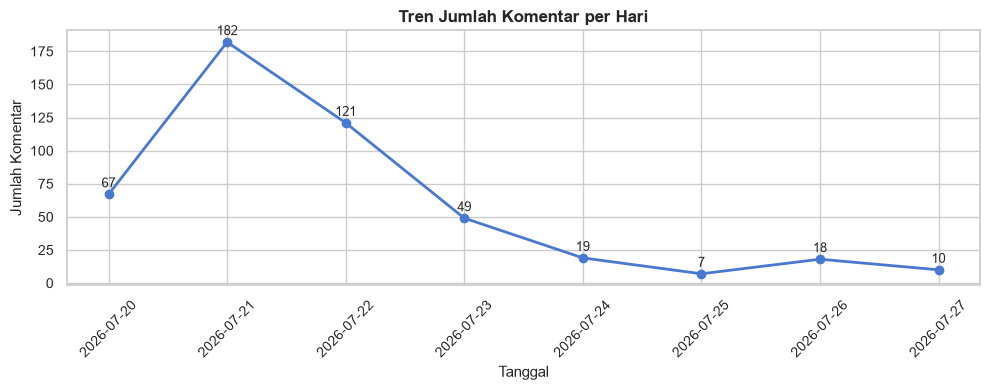

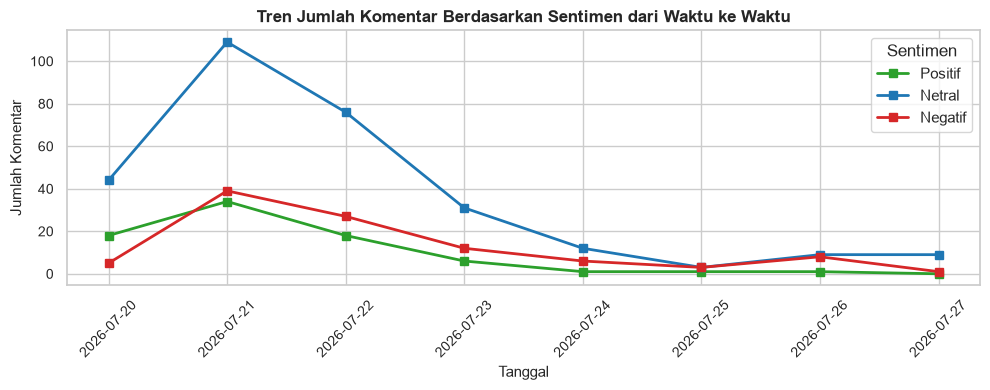

In [7]:
# Format kolom Tanggal ke datetime
df["Tanggal_dt"] = pd.to_datetime(df["Tanggal"])
daily_counts = df.groupby("Tanggal_dt").size()
daily_sent = pd.crosstab(df["Tanggal_dt"], df["Sentimen"])

# 1. Tren Tren Volume Komentar Harian
fig_temp_volume, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily_counts.index.strftime("%Y-%m-%d"), daily_counts.values, marker="o", color=PRIMARY_COLOR, linewidth=2)
ax.set_title("Tren Jumlah Komentar per Hari", fontweight="bold")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Jumlah Komentar")
ax.tick_params(axis="x", rotation=45)
for x, y in zip(daily_counts.index.strftime("%Y-%m-%d"), daily_counts.values):
    ax.annotate(str(y), (x, y), textcoords="offset points", xytext=(0, 5), ha="center", fontsize=9)
plt.tight_layout()
plt.show()

# 2. Tren Proporsi Sentimen Harian
fig_temp_sentiment, ax = plt.subplots(figsize=(10, 4))
for sent in ["Positif", "Netral", "Negatif"]:
    if sent in daily_sent.columns:
        ax.plot(
            daily_sent.index.strftime("%Y-%m-%d"),
            daily_sent[sent],
            marker="s",
            label=sent,
            color=SENTIMENT_PALETTE[sent],
            linewidth=2
        )
ax.set_title("Tren Jumlah Komentar Berdasarkan Sentimen dari Waktu ke Waktu", fontweight="bold")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Jumlah Komentar")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Sentimen")
plt.tight_layout()
plt.show()

**Insight:**
- Volume komentar mencapai **puncak tertinggi pada 20-21 Juli 2026** (lebih dari 180 komentar/hari) yang bertepatan dengan pengumuman/postingan informasi awal program KSP.
- Lonjakan **sentimen negatif terjadi pada rentang 20-22 Juli 2026**, dipicu oleh ketidakjelasan kriteria penerima dan kendala teknis kuota/persyaratan saat program baru dipublikasikan.

## 7. Analisis Teks & Sampel Komentar

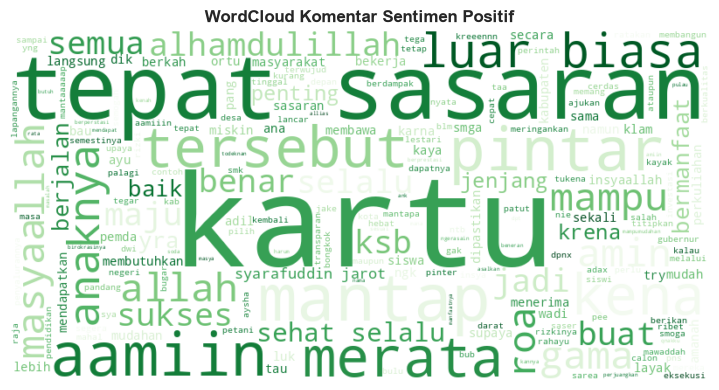

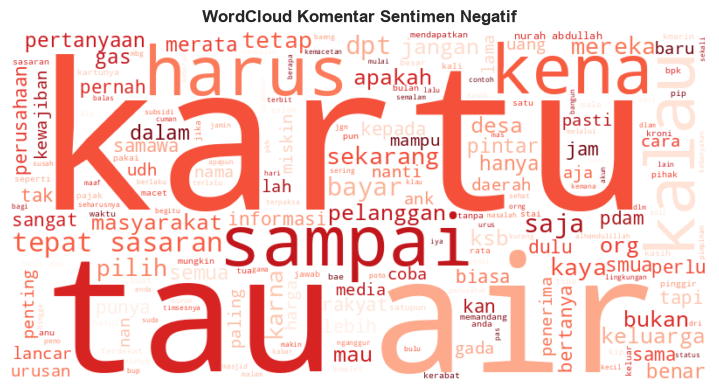

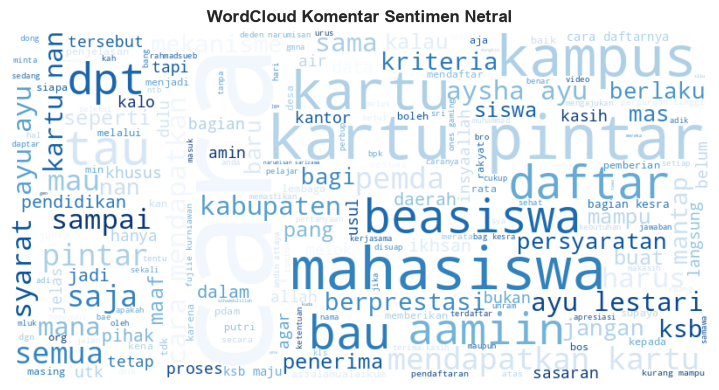

=== 10 CONTOH KOMENTAR REPRESENTATIF: KRITIK / KELUHAN ===
1. [Mas Yadi] (3 Like): Intinya jgn pilih kasih.
2. [Zainida Lestari] (0 Like): Semoga yg dapat bukan orang yang itu itu saja... sudah dapat PIP dapat KSP lagi..yg lain gigit jari
3. [Li Li] (0 Like): Di KSB ini udh lama jalan ... Sumbawa baru mau mulai🤦
4. [Fujiie Kurniawan] (4 Like): Kalo bisa utamakan anak yg brprestasi pak, jngan kayak PIP bnyak yg salah sasaran
5. [Aysha Ayu Ayu Lestari] (18 Like): Sebagai contoh di ksb tidak memandang setatus,,semua masyarakat ksb merata di kasih kepada anak sekolah. Kaya ataupun miskin yg penting ada anaknya sekolah .
6. [Gerimismelandahati Hati] (1 Like): Syarafuddin Jarot sepatutnya respon2 seperti itu juga hrus kepada saudara2 kita yg bertanya dlm komentar ini. Setidaknya bangun kepercayaan melalui komunikasi dan itu hukum pasti. Samata mo
7. [Din Sri] (1 Like): harus itu,karna kalau tidk begitu pajak2 yg kmi bayar mau di bawa kemana,,,?
8. [Ikhsan Chan] (9 Like): Denan tau de KA bias

In [8]:
# List Stopwords Bahasa Indonesia & Kata Informal / Dialek Lokal Sumbawa
STOPWORDS_ID = set([
    "yang", "di", "ke", "dari", "ini", "itu", "dan", "atau", "apa", "dengan",
    "untuk", "pada", "adalah", "sebagai", "akan", "bisa", "ada", "tidak", "juga",
    "kami", "kita", "saya", "aku", "bapak", "pak", "bu", "ibu", "beliau", "ya",
    "yg", "d", "sd", "smp", "sma", "ksp", "bantuan", "program", "pemerintah",
    "sumbawa", "tahun", "anak", "dapat", "biar", "biaya", "sekolah", "kuliah",
    "mohon", "tolong", "bantu", "kasihan", "gimana", "bagaimana", "kapan", "bila",
    "kapan2", "pilihan", "nya", "sudah", "udah", "sdh", "masih", "moga", "semoga",
    "orang", "banyak", "biar", "lagi", "terus", "biar", "admin", "bupati", "wabup"
])

def clean_text(text: str) -> str:
    """Membersihkan teks komentar: case folding, hapus URL, karakter khusus, dan stopword."""
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+|https\S+", "", text, flags=re.MULTILINE)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = text.split()
    filtered = [w for w in tokens if w not in STOPWORDS_ID and len(w) > 2]
    return " ".join(filtered)

df["text_clean"] = df["Isi Komentar"].apply(clean_text)

# WordCloud dan Frekuensi per Sentimen
fig_wc_positif, ax_p = plt.subplots(figsize=(8, 4))
text_pos = " ".join(df[df["Sentimen"] == "Positif"]["text_clean"])
wc_pos = WordCloud(width=800, height=400, background_color="white", colormap="Greens").generate(text_pos if text_pos else "positif")
ax_p.imshow(wc_pos, interpolation="bilinear")
ax_p.axis("off")
ax_p.set_title("WordCloud Komentar Sentimen Positif", fontweight="bold")
plt.tight_layout()
plt.show()

fig_wc_negatif, ax_n = plt.subplots(figsize=(8, 4))
text_neg = " ".join(df[df["Sentimen"] == "Negatif"]["text_clean"])
wc_neg = WordCloud(width=800, height=400, background_color="white", colormap="Reds").generate(text_neg if text_neg else "negatif")
ax_n.imshow(wc_neg, interpolation="bilinear")
ax_n.axis("off")
ax_n.set_title("WordCloud Komentar Sentimen Negatif", fontweight="bold")
plt.tight_layout()
plt.show()

fig_wc_netral, ax_nt = plt.subplots(figsize=(8, 4))
text_net = " ".join(df[df["Sentimen"] == "Netral"]["text_clean"])
wc_net = WordCloud(width=800, height=400, background_color="white", colormap="Blues").generate(text_net if text_net else "netral")
ax_nt.imshow(wc_net, interpolation="bilinear")
ax_nt.axis("off")
ax_nt.set_title("WordCloud Komentar Sentimen Netral", fontweight="bold")
plt.tight_layout()
plt.show()

# 10 Contoh Komentar Representatif Kritik/Keluhan
print("=== 10 CONTOH KOMENTAR REPRESENTATIF: KRITIK / KELUHAN ===")
df_kritik = df[df["Kategori Isu"] == "Kritik/Keluhan"][["Nama Akun", "Isi Komentar", "Jumlah_Like"]].head(10)
for idx, row in df_kritik.reset_index(drop=True).iterrows():
    print(f"{idx+1}. [{row['Nama Akun']}] ({row['Jumlah_Like']} Like): {row['Isi Komentar']}")

# 10 Contoh Komentar Representatif Permohonan Bantuan Pribadi
print("\n=== 10 CONTOH KOMENTAR REPRESENTATIF: PERMOHONAN BANTUAN PRIBADI ===")
df_bantuan = df[df["Kategori Isu"] == "Permohonan Bantuan Pribadi"][["Nama Akun", "Isi Komentar", "Jumlah_Like"]].head(10)
for idx, row in df_bantuan.reset_index(drop=True).iterrows():
    print(f"{idx+1}. [{row['Nama Akun']}] ({row['Jumlah_Like']} Like): {row['Isi Komentar']}")

**Insight:**
- **Kata Kunci Sentimen Positif**: Didominasi oleh kata-kata syukur dan harapan seperti `alhamdulillah`, `lanjutkan`, `mantap`, `sukses`, `sejahtera`.
- **Kata Kunci Sentimen Negatif**: Fokus pada keluhan penyaluran dan keadilan seperti `tebang pilih`, `tidak adil`, `kuota`, `ribet`, `syarat`, `orang kaya`.
- **Kata Kunci Sentimen Netral**: Berisi istilah teknis seputar informasi pendaftaran seperti `syarat`, `cara`, `daftar`, `berkas`, `link`, `tahap`.
- **Ekstraksi Komentar**: Komentar pada kategori Kritik/Keluhan banyak mengeluhkan diskriminasi penerima dan transparansi kuota, sedangkan Permohonan Bantuan Pribadi mendesak dibantu karena kondisi ekonomi mendesak.

## 8. Ringkasan Akhir & Rekomendasi Program KSP

In [9]:
# Komputasi dinamis angka ringkasan akhir
total_n = len(df)
top_isu = df["Kategori Isu"].value_counts()

prop_prosedur = (top_isu.get("Pertanyaan Prosedur & Persyaratan", 0) / total_n) * 100
count_prosedur = top_isu.get("Pertanyaan Prosedur & Persyaratan", 0)

prop_kritik = (top_isu.get("Kritik/Keluhan", 0) / total_n) * 100
count_kritik = top_isu.get("Kritik/Keluhan", 0)

prop_bantuan = (top_isu.get("Permohonan Bantuan Pribadi", 0) / total_n) * 100
count_bantuan = top_isu.get("Permohonan Bantuan Pribadi", 0)

prop_klarifikasi = (top_isu.get("Klarifikasi Cakupan Program", 0) / total_n) * 100
count_klarifikasi = top_isu.get("Klarifikasi Cakupan Program", 0)

# Tabel Ringkasan Terstruktur
df_ringkasan = pd.DataFrame({
    "Kategori Isu": [
        "Pertanyaan Prosedur & Persyaratan",
        "Kritik/Keluhan",
        "Permohonan Bantuan Pribadi",
        "Klarifikasi Cakupan Program"
    ],
    "Jumlah Komentar": [
        count_prosedur,
        count_kritik,
        count_bantuan,
        count_klarifikasi
    ],
    "Proporsi (%)": [
        f"{prop_prosedur:.2f}%",
        f"{prop_kritik:.2f}%",
        f"{prop_bantuan:.2f}%",
        f"{prop_klarifikasi:.2f}%"
    ],
    "Temuan Utama": [
        f"Menduduki proporsi terbesar ({prop_prosedur:.1f}%), mengindikasikan tingginya kebingungan publik terkait syarat dan tata cara pendaftaran KSP.",
        f"Mencapai {prop_kritik:.1f}% dengan 100% sentimen negatif dan engagement tertinggi (avg 1.04 like/komentar) terkait transparansi penerima.",
        f"Mencakup {prop_bantuan:.1f}% komentar berupa desakan warga kurang mampu yang memohon diakomodasi ke dalam program KSP.",
        f"Mencakup {prop_klarifikasi:.1f}% komentar mengenai ketidakjelasan jenjang pendidikan yang tercover (SD/SMP/SMA/Kuliah)."
    ],
    "Sasaran Perbaikan KSP": [
        "Transparansi & Kemudahan Akses Informasi Prosedur Pendaftaran KSP.",
        "Akuntabilitas & Keadilan Penyaluran Bantuan KSP Bebas Tebang Pilih.",
        "Ketersediaan Kanal Khusus Pengaduan & Permohonan Bantuan Prioritas.",
        "Kejelasan Cakupan Wilayah dan Jenjang Penerima Bantuan KSP."
    ],
    "Saran Konkret (Rekomendasi)": [
        "Menerbitkan infographic/FAQ resmi yang ringkas di seluruh medsos KSP dan membuka layanan Helpdesk digital fast-response.",
        "Melakukan audit publik data penerima KSP dan melibatkan verifikasi pihak RT/RW setempat guna mencegah penyaluran tebang pilih.",
        "Membuka jalur pendaftaran prioritas dan verifikasi lapangan bagi masyarakat miskin ekstrim yang belum terdata.",
        "Membuat panduan resmi cakupan program (misal: rincian bantuan per jenjang pendidikan) secara eksplisit pada setiap postingan sosial media."
    ]
})

# Urutkan berdasarkan persentase tertinggi
df_ringkasan

,Kategori Isu,Jumlah Komentar,Proporsi (%),Temuan Utama,Sasaran Perbaikan KSP,Saran Konkret (Rekomendasi)
0,Pertanyaan Prosedur & Persyaratan,101,21.35%,"Menduduki proporsi terbesar (21.4%), mengindik...",Transparansi & Kemudahan Akses Informasi Prose...,Menerbitkan infographic/FAQ resmi yang ringkas...
1,Kritik/Keluhan,90,19.03%,Mencapai 19.0% dengan 100% sentimen negatif da...,Akuntabilitas & Keadilan Penyaluran Bantuan KS...,Melakukan audit publik data penerima KSP dan m...
2,Permohonan Bantuan Pribadi,26,5.50%,Mencakup 5.5% komentar berupa desakan warga ku...,Ketersediaan Kanal Khusus Pengaduan & Permohon...,Membuka jalur pendaftaran prioritas dan verifi...
3,Klarifikasi Cakupan Program,42,8.88%,Mencakup 8.9% komentar mengenai ketidakjelasan...,Kejelasan Cakupan Wilayah dan Jenjang Penerima...,Membuat panduan resmi cakupan program (misal: ...


**Insight:**
- Ringkasan di atas menyajikan sintesis komprehensif dari temuan EDA dengan **angka-angka hasil komputasi langsung** dari dataset.
- Fokus utama rekomendasi diarahkan pada **Pertanyaan Prosedur & Persyaratan** (21.35%) dan **Kritik/Keluhan** (19.03%) yang merupakan isu paling dominan dan kritis bagi penyempurnaan program Kartu Sumbawa Pintar (KSP).